# Insurance Claims Insight - Round 2

Synthetic academic dataset, seed 42. Four main source tables and one region lookup. This notebook covers cleaning, EDA, business answers and feature engineering. All included code cells were executed with a shared Python namespace. Use Run All in Jupyter or VS Code to reproduce the work.

In [1]:
from pathlib import Path
import sys
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise FileNotFoundError('Start Jupyter in the extracted project folder.')
sys.path.insert(0, str(ROOT))
print('Project:', ROOT.name)


Project: insurance_round2


## 1. Load and understand the source data
Claims is the analysis grain. Policies can have several claims; incidents and processing have one row per unique claim in this sample.

In [2]:
raw = {name: pd.read_csv(ROOT / 'data/raw' / (name + '.csv')) for name in ['claims','policies','incidents','processing','regions']}
for name, table in raw.items():
    print('\n' + name, table.shape)
    print(table.dtypes.to_string())
print('\nSample claims')
print(raw['claims'].head().to_string(index=False))


claims (3020, 6)
claim_id        object
policy_id       object
incident_id     object
claim_date      object
amount         float64
status          object

policies (1620, 5)
policy_id       object
policy_type     object
premium        float64
tenure           int64
region_id       object

incidents (3020, 4)
incident_id      object
incident_type    object
location         object
severity         object

processing (3020, 4)
claim_id                   object
stages                      int64
settlement_days           float64
investigation_required      int64

regions (5, 2)
region_id      object
region_name    object

Sample claims
claim_id policy_id incident_id claim_date   amount   status
  C00001    P00671      I00001 not-a-date 28534.95  Settled
  C00002    P99999      I00002 2025-09-19 37810.45  Settled
  C00003    P00821      I00003 2025-04-24 71396.39  Settled
  C00004    P00421      I00004 2025-10-28 17903.29 Rejected
  C00005    P00173      I00005 2025-10-20 19057.87  Pending

## 2. Raw data quality audit
Count missing values and duplicate records before changing any values. Repeated keys are deliberate exact duplicates in the generated sample.

In [3]:
keys = {'claims':'claim_id','policies':'policy_id','incidents':'incident_id','processing':'claim_id','regions':'region_id'}
for name, table in raw.items():
    print('\n' + name)
    print('Duplicate keys:', table.duplicated(keys[name]).sum())
    print('Missing fields:', table.isna().sum().to_dict())
print('Negative amounts:', raw['claims'].amount.lt(0).sum())
print('Negative settlement durations:', raw['processing'].settlement_days.lt(0).sum())


claims
Duplicate keys: 20
Missing fields: {'claim_id': 0, 'policy_id': 0, 'incident_id': 0, 'claim_date': 0, 'amount': 44, 'status': 0}

policies
Duplicate keys: 20
Missing fields: {'policy_id': 0, 'policy_type': 0, 'premium': 0, 'tenure': 0, 'region_id': 0}

incidents
Duplicate keys: 20
Missing fields: {'incident_id': 0, 'incident_type': 40, 'location': 0, 'severity': 60}

processing
Duplicate keys: 20
Missing fields: {'claim_id': 0, 'stages': 0, 'settlement_days': 680, 'investigation_required': 0}

regions
Duplicate keys: 0
Missing fields: {'region_id': 0, 'region_name': 0}
Negative amounts: 16
Negative settlement durations: 25


## 3. Clean, merge and engineer features
The cleaning implementation below is the exact source file used by the pipeline. Missing outcomes are never imputed. The lookup joins validate their expected cardinality.

In [4]:
from pathlib import Path
import numpy as np
import pandas as pd

# ROOT was resolved in the setup cell.


def clean():
    raw = ROOT / 'data' / 'raw'
    out = ROOT / 'data' / 'cleaned'
    out.mkdir(parents=True, exist_ok=True)
    log = []
    tables = {}
    keys = {'claims':'claim_id', 'policies':'policy_id', 'incidents':'incident_id',
            'processing':'claim_id', 'regions':'region_id'}
    for name, key in keys.items():
        df = pd.read_csv(raw / f'{name}.csv')
        log.append({'table':name,'check':'raw_rows','count':len(df)})
        duplicates = df.duplicated(key)
        log.append({'table':name,'check':'duplicate_keys_removed','count':int(duplicates.sum())})
        df = df.drop_duplicates(key).copy()
        for col in df.select_dtypes('object'):
            df[col] = df[col].str.strip()
        for col in ['status','policy_type','incident_type','severity']:
            if col in df:
                df[col] = df[col].str.title()
        tables[name] = df
    c,p,i,s,r = [tables[x] for x in keys]
    c['claim_date'] = pd.to_datetime(c.claim_date,format='%Y-%m-%d',errors='coerce')
    log.append({'table':'claims','check':'invalid_or_missing_dates_retained','count':int(c.claim_date.isna().sum())})
    for name, df, cols in [('claims',c,['amount']),('policies',p,['premium','tenure']),
                           ('processing',s,['stages','settlement_days'])]:
        for col in cols:
            df[col] = pd.to_numeric(df[col],errors='coerce')
            bad = df[col].lt(0)
            log.append({'table':name,'check':f'negative_{col}_set_missing','count':int(bad.sum())})
            df.loc[bad,col] = np.nan
            log.append({'table':name,'check':f'missing_{col}_after_validation','count':int(df[col].isna().sum())})
    for col in ['incident_type','severity']:
        log.append({'table':'incidents','check':f'missing_{col}_marked_unknown','count':int(i[col].isna().sum())})
        i[col] = i[col].fillna('Unknown')
    joined = c.merge(p,on='policy_id',how='left',validate='many_to_one',indicator='policy_match')
    joined = joined.merge(i,on='incident_id',how='left',validate='many_to_one',indicator='incident_match')
    joined = joined.merge(s,on='claim_id',how='left',validate='one_to_one',indicator='processing_match')
    joined = joined.merge(r,on='region_id',how='left',validate='many_to_one')
    joined['unmatched_policy'] = joined.policy_match.eq('left_only').astype(int)
    joined['unmatched_incident'] = joined.incident_match.eq('left_only').astype(int)
    log.append({'table':'merged','check':'unmatched_policies_retained','count':int(joined.unmatched_policy.sum())})
    joined['region_name'] = joined.region_name.fillna('Unknown')
    joined['policy_type'] = joined.policy_type.fillna('Unknown')
    joined['amount_missing'] = joined.amount.isna().astype(int)
    # Preserve observed amount for financial EDA; fill a separate feature only.
    group_median = joined.groupby('policy_type').amount.transform('median')
    joined['amount_filled'] = joined.amount.fillna(group_median).fillna(joined.amount.median())
    joined['claim_month'] = joined.claim_date.dt.to_period('M').astype('string')
    joined['claim_quarter'] = joined.claim_date.dt.quarter
    joined['is_settled'] = joined.status.eq('Settled').astype(int)
    joined['delayed_claim'] = pd.Series(pd.NA,index=joined.index,dtype='Int64')
    eligible = joined.is_settled.eq(1) & joined.settlement_days.notna()
    joined.loc[eligible,'delayed_claim'] = joined.loc[eligible,'settlement_days'].gt(30).astype(int)
    joined['amount_to_premium'] = joined.amount / joined.premium.where(joined.premium.gt(0))
    q1,q3 = joined.amount.quantile([.25,.75])
    fence = q3 + 1.5*(q3-q1)
    joined['amount_outlier'] = joined.amount.gt(fence).astype(int)
    joined['amount_band'] = pd.cut(joined.amount_filled,[0,25000,100000,float('inf')],labels=['Low','Medium','High'])
    joined['severity_rank'] = joined.severity.map({'Low':1,'Medium':2,'High':3})
    for name,df in tables.items():
        df.to_csv(out / f'{name}.csv',index=False)
    joined.to_csv(out / 'claims_analysis.csv',index=False)
    encoded = pd.get_dummies(joined[['amount_filled','amount_missing','premium','tenure','severity_rank',
                                    'policy_type','region_name','incident_type','severity','amount_band']],
                              columns=['policy_type','region_name','incident_type','severity','amount_band'],dtype=int)
    encoded.insert(0,'claim_id',joined.claim_id)
    encoded.to_csv(out / 'claim_features.csv',index=False)
    pd.DataFrame(log).to_csv(ROOT / 'outputs' / 'tables' / 'cleaning_log.csv',index=False)
    joined.isna().sum().rename('missing_count').to_csv(ROOT / 'outputs' / 'tables' / 'missing_values.csv')
    assert joined.claim_id.is_unique and len(joined) == len(c)
    assert joined.amount.dropna().ge(0).all()
    assert joined.settlement_days.dropna().ge(0).all()
    assert joined.loc[joined.is_settled.eq(0),'delayed_claim'].isna().all()
    print(f'Cleaned and joined {len(joined):,} claims; missing outcomes retained.')
    return joined



df = clean()
print(df.head().to_string(index=False))
print(pd.read_csv(ROOT / 'outputs/tables/cleaning_log.csv').to_string(index=False))

Cleaned and joined 3,000 claims; missing outcomes retained.
claim_id policy_id incident_id claim_date   amount   status policy_type  premium  tenure region_id policy_match incident_type location severity incident_match  stages  settlement_days  investigation_required processing_match region_name  unmatched_policy  unmatched_incident  amount_missing  amount_filled claim_month  claim_quarter  is_settled  delayed_claim  amount_to_premium  amount_outlier amount_band  severity_rank
  C00001    P00671      I00001        NaT 28534.95  Settled       Motor 13606.28     2.0       R01         both         Theft      R01      Low           both     NaN             20.0                       1             both       South                 0                   0               0       28534.95        <NA>            NaN           1              0           2.097190               0      Medium            1.0
  C00002    P99999      I00002 2025-09-19 37810.45  Settled     Unknown      NaN     NaN       N

## 4. Descriptive EDA and charts
Monetary summaries use original observed amounts. The full plotting and grouped-analysis implementation follows. Settlement-duration comparisons use settled claims with valid durations.

In [5]:
from pathlib import Path
import html
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import seaborn as sns

# ROOT was resolved in the setup cell.


def analyse():
    df = pd.read_csv(ROOT / 'data' / 'cleaned' / 'claims_analysis.csv',parse_dates=['claim_date'])
    tables = ROOT / 'outputs' / 'tables'
    charts = ROOT / 'outputs' / 'charts'
    sns.set_theme(style='whitegrid',palette='deep')
    plt.rcParams.update({'figure.figsize':(9,5),'axes.titleweight':'bold'})
    images = []

    def save(name,title,xlabel=None,ylabel=None):
        plt.title(title + '\nSynthetic insurance data',loc='left')
        if xlabel:
            plt.xlabel(xlabel)
        if ylabel:
            plt.ylabel(ylabel)
        plt.tight_layout()
        plt.savefig(charts / f'{name}.png',dpi=180)
        plt.close()
        images.append((name,title))

    df.describe(include='all').to_csv(tables / 'descriptive_statistics.csv')
    settled = df[df.status.eq('Settled') & df.settlement_days.notna()].copy()
    summaries = {}
    for col in ['policy_type','region_name','incident_type','severity']:
        summary = df.groupby(col,dropna=False).agg(
            claims=('claim_id','size'), observed_amounts=('amount','count'),
            mean_amount=('amount','mean'), median_amount=('amount','median'),
            total_observed_amount=('amount','sum'),
            mean_stages=('stages','mean'), investigation_rate=('investigation_required','mean'))
        outcome = settled.groupby(col).agg(settled_valid_n=('claim_id','size'),
                                           mean_settlement_days=('settlement_days','mean'),
                                           median_settlement_days=('settlement_days','median'),
                                           delay_rate=('delayed_claim','mean'))
        summary = summary.join(outcome).sort_values('claims',ascending=False)
        summary.to_csv(tables / f'{col}_summary.csv')
        summaries[col] = summary
    monthly = df.dropna(subset=['claim_date']).groupby('claim_month').agg(
        claims=('claim_id','size'), mean_amount=('amount','mean'))
    monthly.to_csv(tables / 'monthly_trend.csv')
    sns.histplot(df.amount.dropna(),bins=45)
    save('01_amount_distribution','Claim amount distribution','Claim amount (INR)','Number of claims')
    sns.countplot(data=df,x='status',order=df.status.value_counts().index)
    save('02_status_counts','Claim status distribution','Status','Number of claims')
    sns.histplot(settled.settlement_days,bins=30)
    save('03_settlement_distribution','Settlement duration for settled claims','Settlement days','Number of claims')
    sns.barplot(x=summaries['policy_type'].index,y=summaries['policy_type'].mean_amount)
    save('04_amount_by_policy','Average observed claim amount by policy type','Policy type','Mean claim amount (INR)')
    sns.barplot(x=summaries['region_name'].index,y=summaries['region_name'].claims)
    save('05_region_volume','Claim volume by region','Region','Number of claims')
    sns.boxplot(data=settled,x='incident_type',y='settlement_days')
    plt.xticks(rotation=25,ha='right')
    save('06_incident_settlement','Settlement duration by incident type','Incident type','Settlement days')
    monthly.claims.plot(marker='o',color='#245b83')
    plt.xticks(rotation=35,ha='right')
    save('07_monthly_trend','Monthly claim volume','Claim month','Number of claims')
    sns.scatterplot(data=settled,x='amount',y='settlement_days',hue='severity',alpha=.35,s=18)
    save('08_amount_vs_days','Observed amount and settlement time','Claim amount (INR)','Settlement days')
    numeric = df[['amount','premium','tenure','stages','settlement_days','investigation_required','severity_rank']]
    corr = numeric.corr()
    corr.to_csv(tables / 'correlations.csv')
    numeric.notna().astype(int).T.dot(numeric.notna().astype(int)).to_csv(tables / 'correlation_pair_counts.csv')
    sns.heatmap(corr,annot=True,fmt='.2f',cmap='vlag',vmin=-1,vmax=1)
    save('09_correlation','Pearson correlations (pairwise observed values)')
    sns.barplot(x=summaries['incident_type'].index,y=summaries['incident_type'].investigation_rate*100)
    plt.xticks(rotation=25,ha='right')
    save('10_investigation','Investigation rate by incident type','Incident type','Investigated claims (%)')
    delay = summaries['incident_type'].sort_values('delay_rate',ascending=False)
    sns.barplot(x=delay.index,y=delay.delay_rate*100)
    plt.xticks(rotation=25,ha='right')
    save('11_delay_rate','Share exceeding 30 days among valid settled claims','Incident type','Delayed settled claims (%)')
    missing = df[['amount','severity_rank','settlement_days','premium','claim_date']].isna().mean()*100
    missing.plot.bar(color='#c08238')
    plt.xticks(rotation=25,ha='right')
    save('12_missingness','Missing values after cleaning','Field','Missing (%)')

    policy = summaries['policy_type'].drop(index='Unknown',errors='ignore').sort_values('mean_amount',ascending=False)
    region = summaries['region_name'].drop(index='Unknown',errors='ignore').sort_values('claims',ascending=False)
    incident = summaries['incident_type'].drop(index='Unknown',errors='ignore')
    slow = incident.sort_values('mean_settlement_days',ascending=False)
    delays = incident.sort_values('delay_rate',ascending=False)
    effort = incident.sort_values(['investigation_rate','mean_stages'],ascending=False)
    questions = [
        ('Which claim types have higher average value?',
         f'{policy.index[0]} has the highest average observed amount: INR {policy.iloc[0].mean_amount:,.0f}. Policy type is used for claim type; incident-level comparisons are also provided.'),
        ('Which regions generate more claims?',
         f'{region.index[0]} has {int(region.iloc[0].claims):,} claims, the largest count. Counts are not risk rates: policy exposure and insured population differ.'),
        ('What drives longer settlement time?',
         f'{slow.index[0]} has the highest mean settlement duration ({slow.iloc[0].mean_settlement_days:.1f} days). Severity, stage count and investigation show associations in the plots; they do not establish causation.'),
        ('Which stages create delay?',
         'The brief supplies stage count, not timestamps or stage names. More stages can be compared with duration, but a specific bottleneck stage cannot be identified. Capture start/end timestamps for document review, investigation and approval.'),
        ('How do claim values vary by severity?',
         '; '.join(f'{k}: INR {v:,.0f}' for k,v in summaries['severity'].mean_amount.items()) + '. Unknown details remain a separate category.'),
        ('Which categories need more investigation effort?',
         f'{effort.index[0]} has the highest investigation rate ({effort.iloc[0].investigation_rate:.1%}) with {effort.iloc[0].mean_stages:.1f} mean stages. Investigation rate and stage count are proxies; staff-hours are not available.')]
    stage_summary = settled.groupby('stages').agg(claims=('claim_id','size'),mean_days=('settlement_days','mean'),delay_rate=('delayed_claim','mean'))
    stage_summary.to_csv(tables / 'stage_count_summary.csv')
    pd.DataFrame(questions,columns=['question','answer']).to_csv(tables / 'business_answers.csv',index=False)
    findings = [
        '# Round 2: Insurance Claims Insight',
        'All records are generated synthetic data for an academic demonstration. No actual ShieldSure customer records are used. Relationships partly reflect the generator assumptions.',
        f'## Coverage\n{len(df):,} unique claims, {len(settled):,} settled claims with valid duration, calendar year 2025. Currency is assumed INR; tenure is years. Settlement duration is calendar days.',
        '## Cleaning decisions\nDuplicate keys are removed. Category spelling and whitespace are standardised. Negative amount, premium, stage count and duration become missing. Invalid dates are retained as missing. Unknown incidents are explicit. Orphan links stay flagged. Genuine large claims stay in EDA with an IQR outlier flag. Missing amount is filled only in a separate feature; reported monetary statistics use observed values. Non-settled durations are structurally missing and are never imputed.',
        '## Business answers']
    for q,a in questions:
        findings.append(f'### {q}\n{a}')
    findings += [
        f'## Delay priority\n{delays.index[0]} has the highest delay share among valid settled claims ({delays.iloc[0].delay_rate:.1%}). Review investigation handoffs and document completeness in that group. This is a synthetic demonstration, not an operational recommendation based on real evidence.',
        '## Feature engineering\nclaim_month, claim_quarter, amount_missing, amount_filled, amount_band, severity_rank, amount_to_premium, amount_outlier, is_settled, delayed_claim and unmatched-link flags are in claims_analysis.csv. claim_features.csv contains one-hot encoded policy type, region, incident type, severity and amount band. Delay means more than 30 days, an assumed demonstration threshold rather than an insurer SLA.',
        '## Interpretation and limitations\nSettlement summaries exclude pending/rejected records and invalid durations; this creates completed-case selection bias. The time window is based on claim date, not settlement date. Monthly counts exclude invalid dates. Region comparisons lack exposure-adjusted denominators. Correlations are pairwise and descriptive. Unknown severity has no ordinal rank. Reference data is generation provenance only and is never used to repair raw records. No predictive model is claimed. For future modelling, split by time first, fit imputers/encoders on training data only, and exclude settlement-derived fields and processing outcomes from intake predictors.',
        '## Evidence\nSee the 12 charts, category summary tables, descriptive statistics, correlation pair counts, cleaning log, missing-value counts, executed notebook and run_validation.json.']
    text = '\n\n'.join(findings)
    (ROOT / 'reports' / 'findings.md').write_text(text,encoding='utf-8')
    sections = ''.join(f'<h2>{html.escape(q)}</h2><p>{html.escape(a)}</p>' for q,a in questions)
    figures = ''.join(f'<figure><img src="../outputs/charts/{n}.png"><figcaption>{html.escape(t)}</figcaption></figure>' for n,t in images)
    page = '<!doctype html><html><head><meta charset="utf-8"><title>Insurance Claims Insight</title><style>body{font:16px Arial;max-width:1000px;margin:40px auto;padding:20px;color:#183148;background:#f7f9fb}h1,h2{color:#163d61}img{width:100%;height:auto}figure{background:white;padding:15px;border:1px solid #d9e1e8;margin:25px 0}p{line-height:1.6}</style></head><body><h1>Insurance Claims Insight: Round 2</h1><p>Synthetic demonstration | 3,000 unique claims | 2025 | Currency: INR</p>' + sections + '<h2>Visual evidence</h2>' + figures + '<p>See findings.md for cleaning rules, feature definitions and limitations.</p></body></html>'
    (ROOT / 'reports' / 'report.html').write_text(page,encoding='utf-8')
    print('Saved 12 visualisations, summary tables and findings.')



analyse()
print(df[['amount','premium','tenure','stages','settlement_days']].describe().round(2).to_string())

Saved 12 visualisations, summary tables and findings.
           amount   premium   tenure   stages  settlement_days
count     2941.00   2998.00  2999.00  2999.00          2300.00
mean     81307.94  11982.00     5.50     3.69            21.57
std     120892.21   5755.88     2.86     1.26            10.30
min       1341.89   2755.35     1.00     2.00             1.00
25%      21403.75   8063.86     3.00     3.00            14.00
50%      44978.66  10894.13     6.00     4.00            19.00
75%      95390.76  14531.26     8.00     4.00            29.00
max    1836460.58  43338.17    10.00     6.00            53.00


## 5. Univariate, bivariate and operational visual evidence

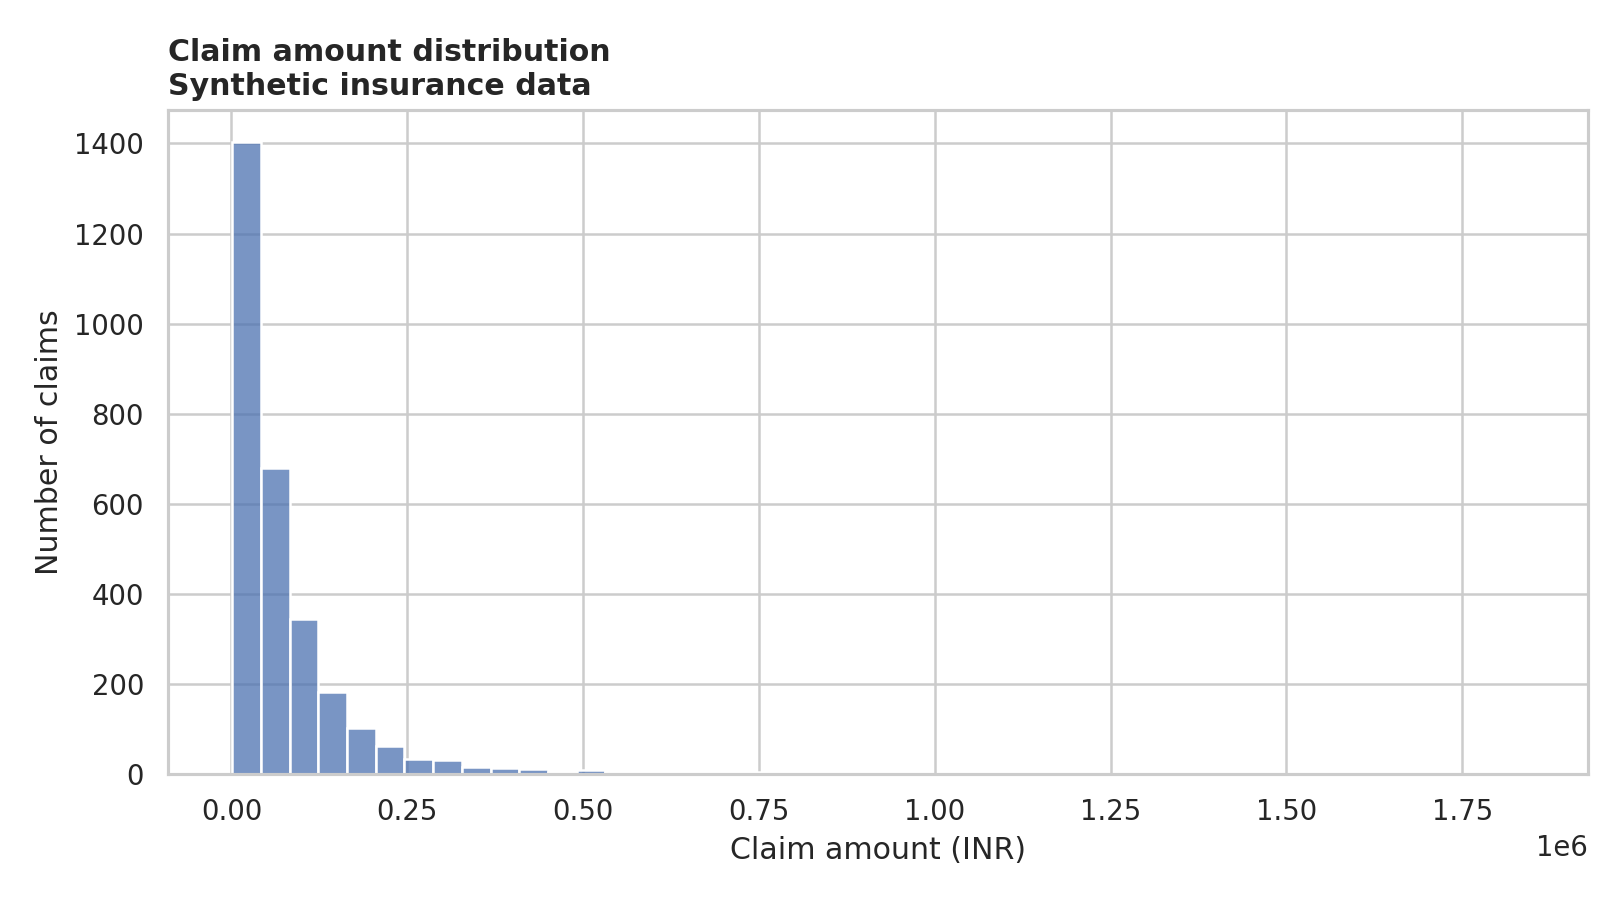

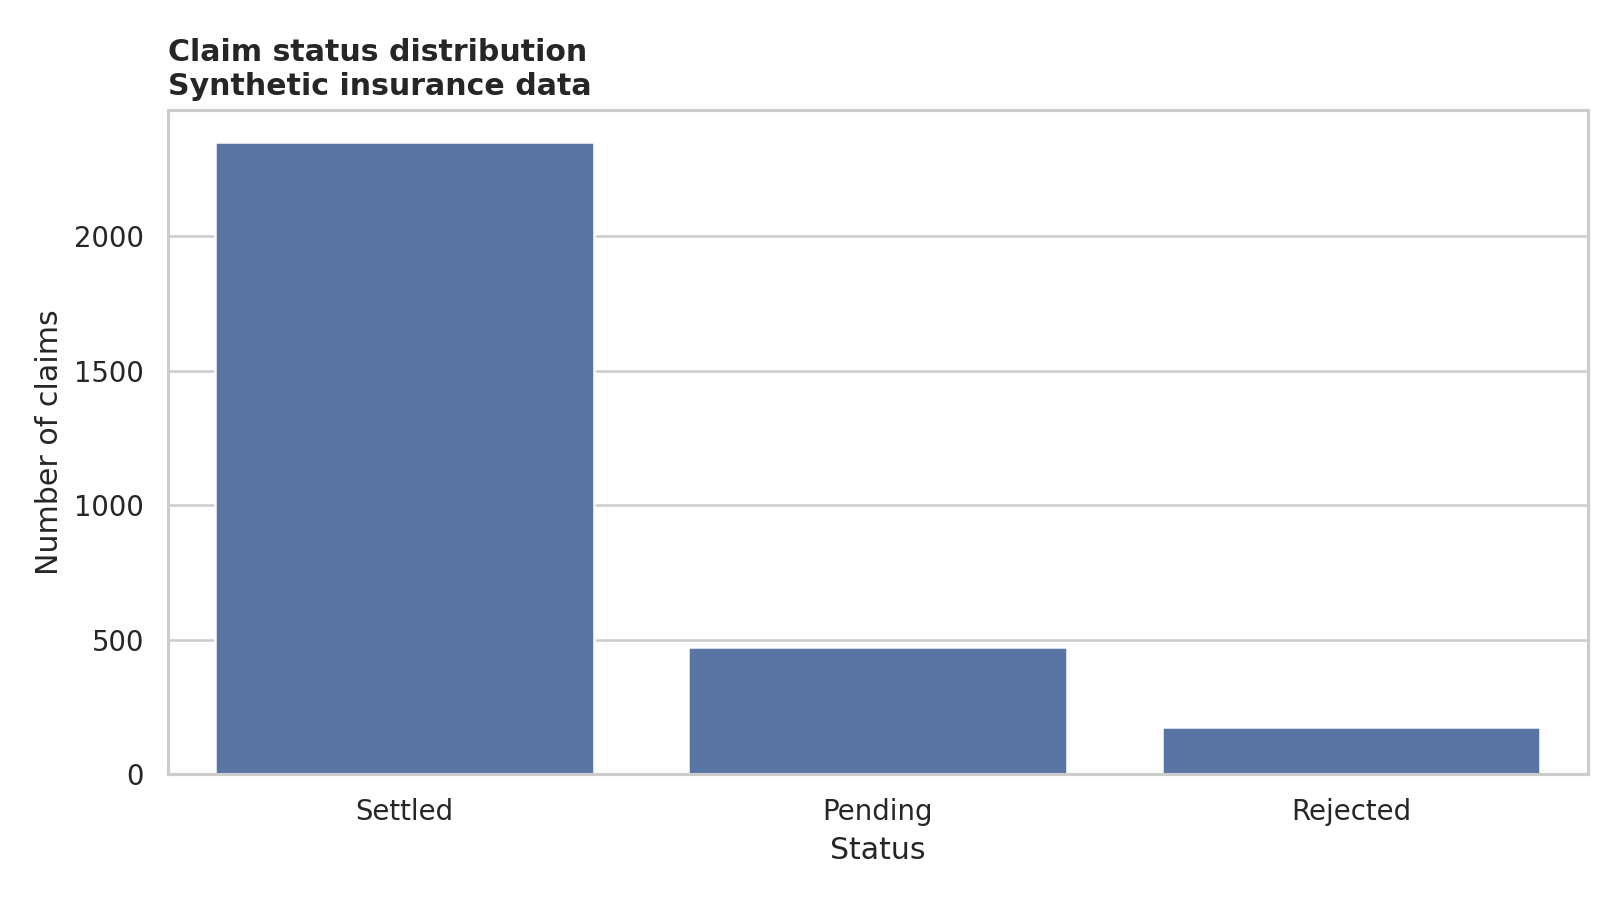

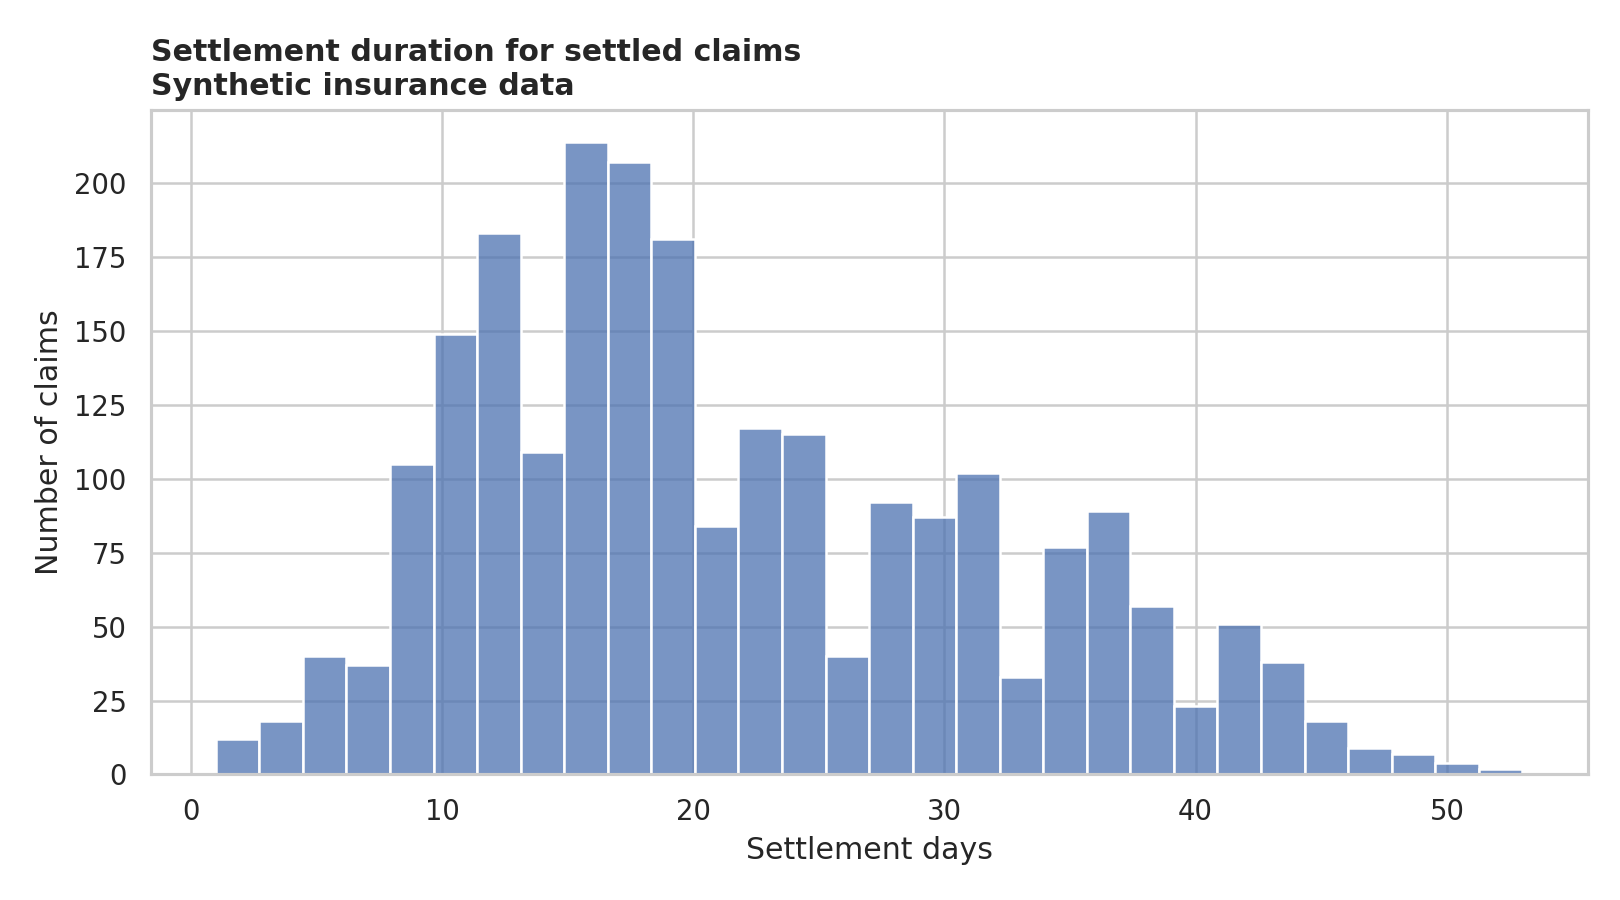

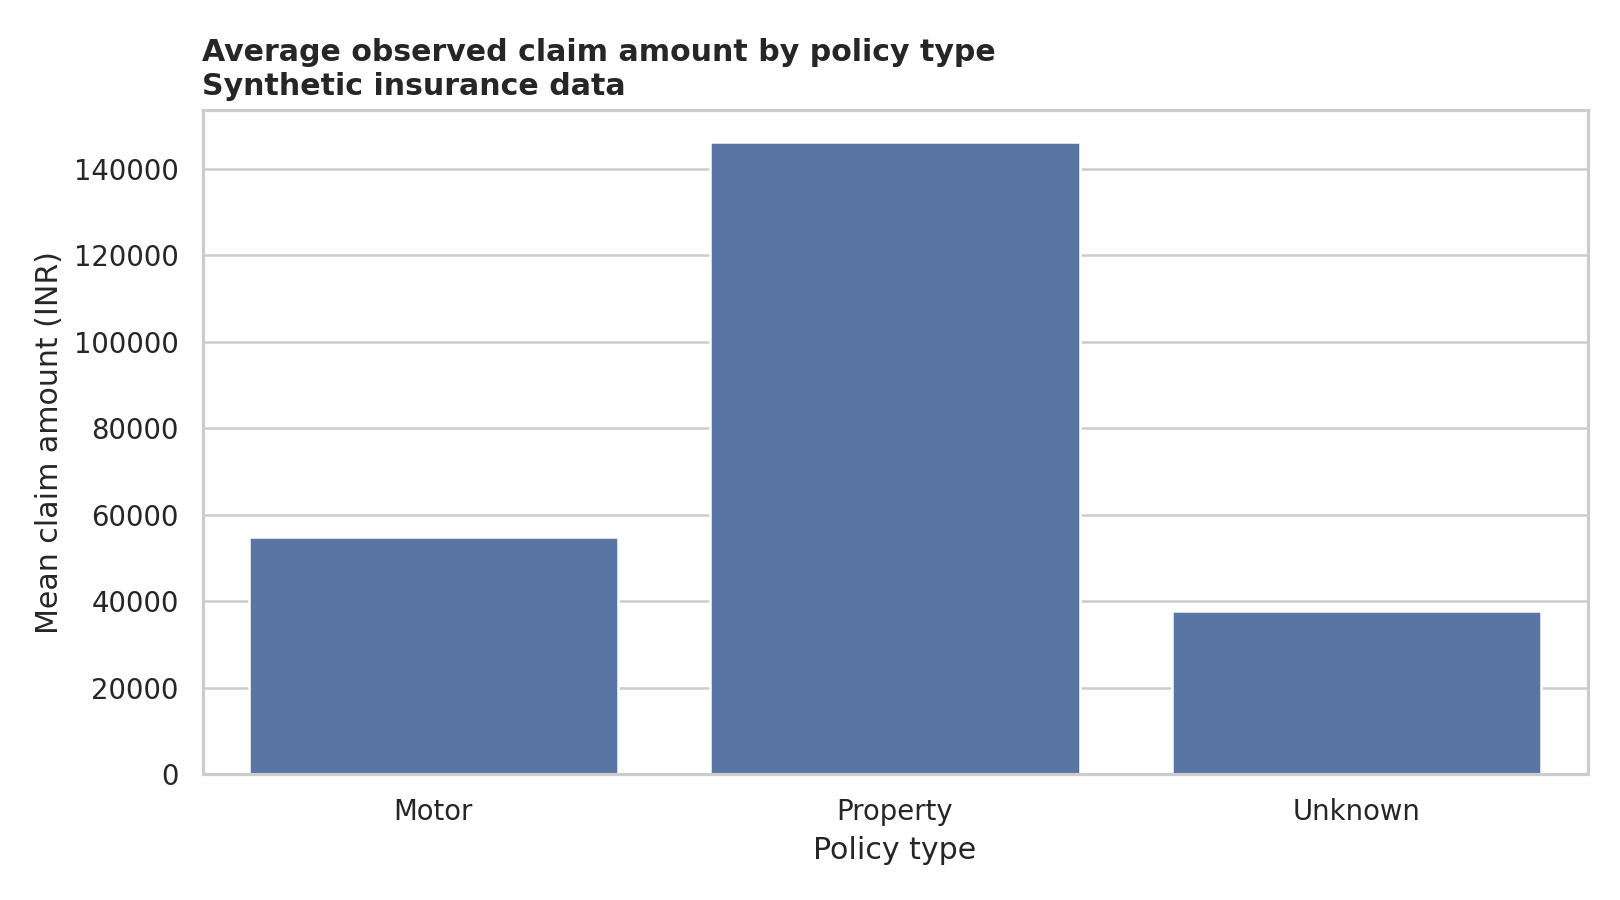

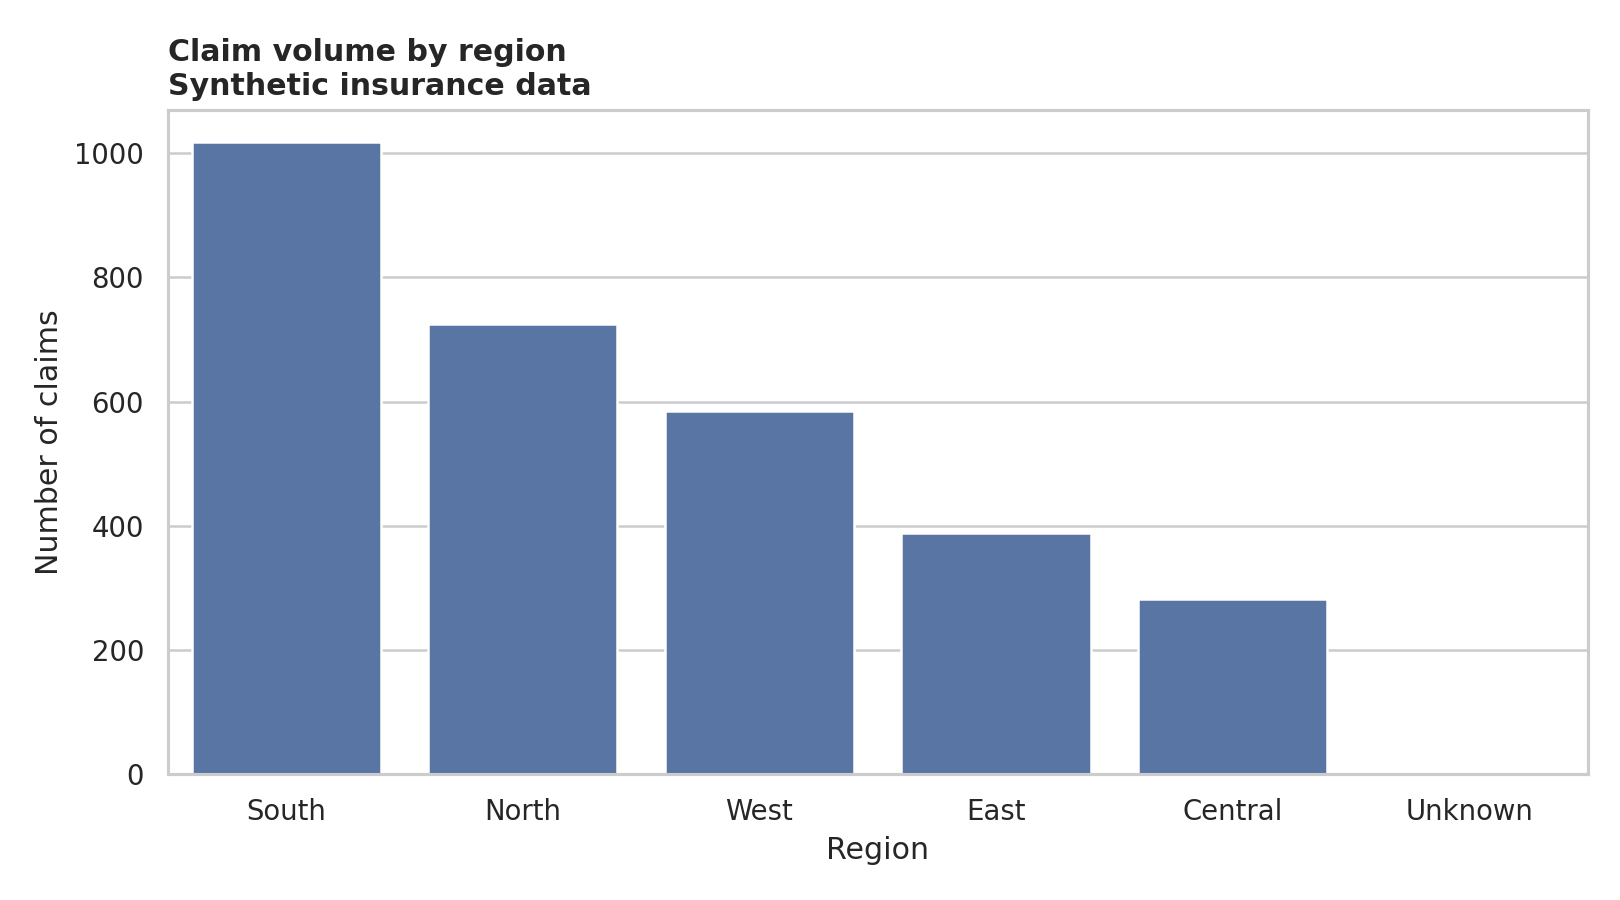

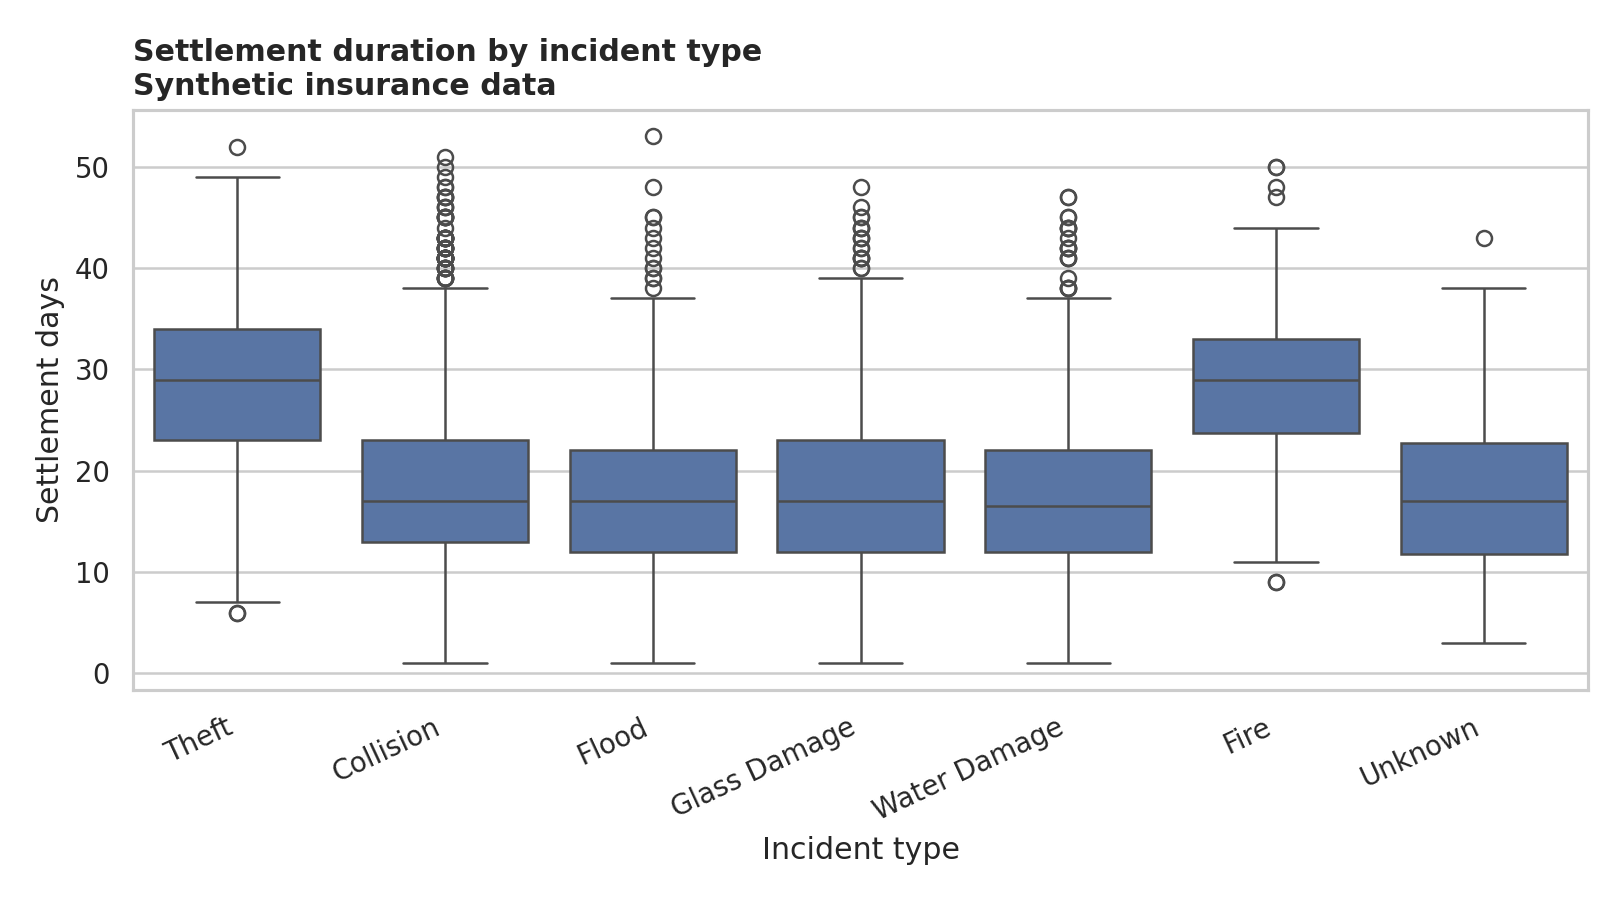

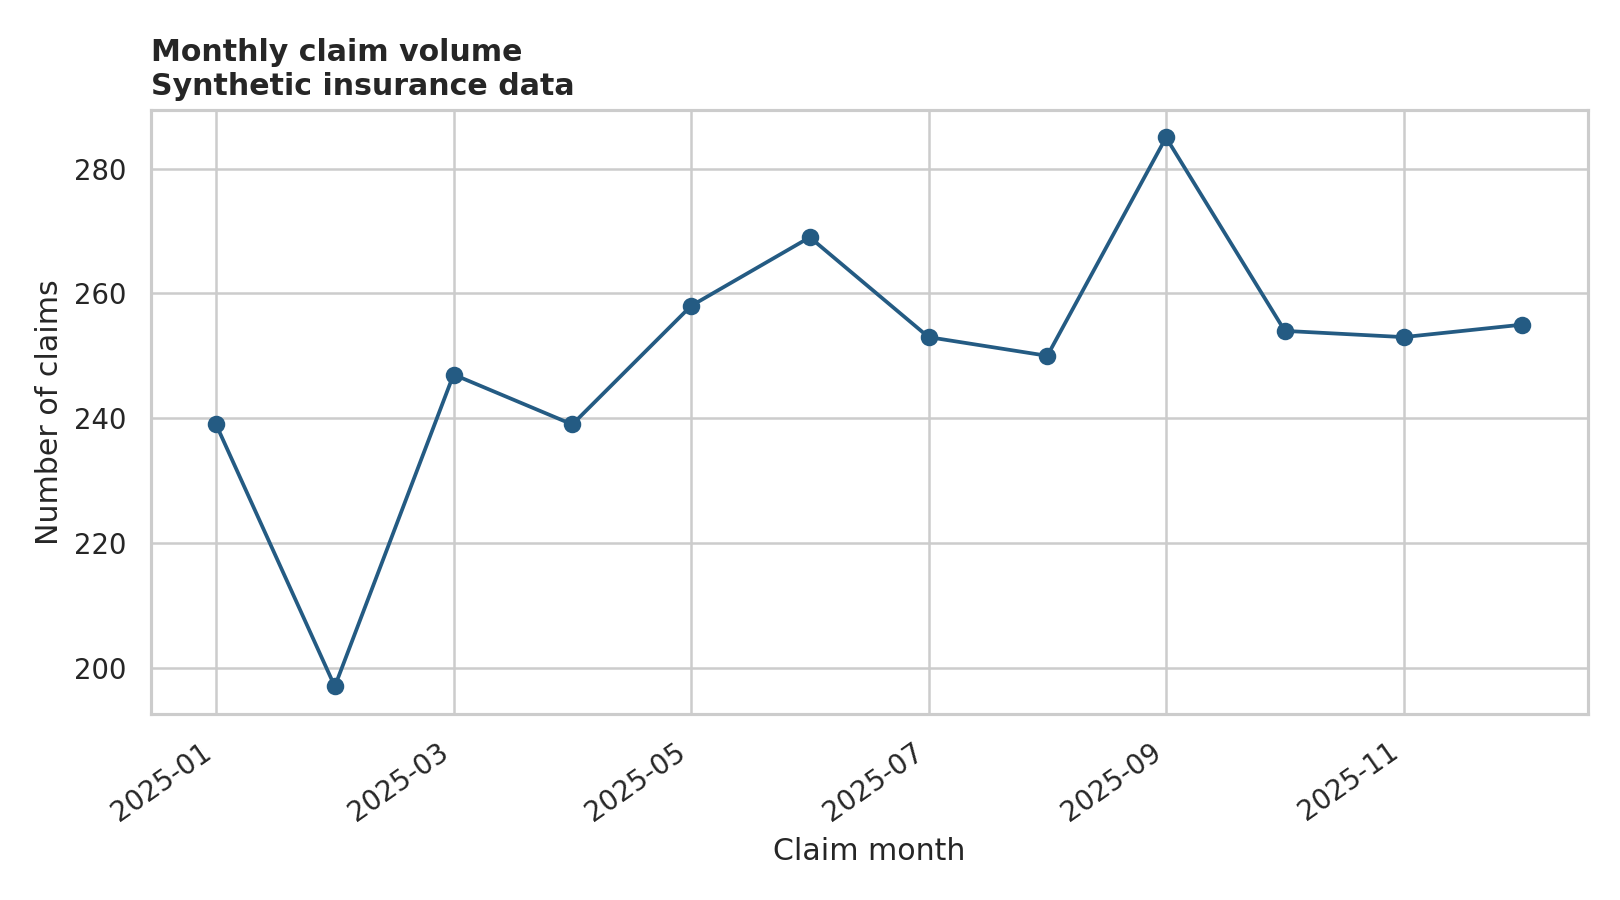

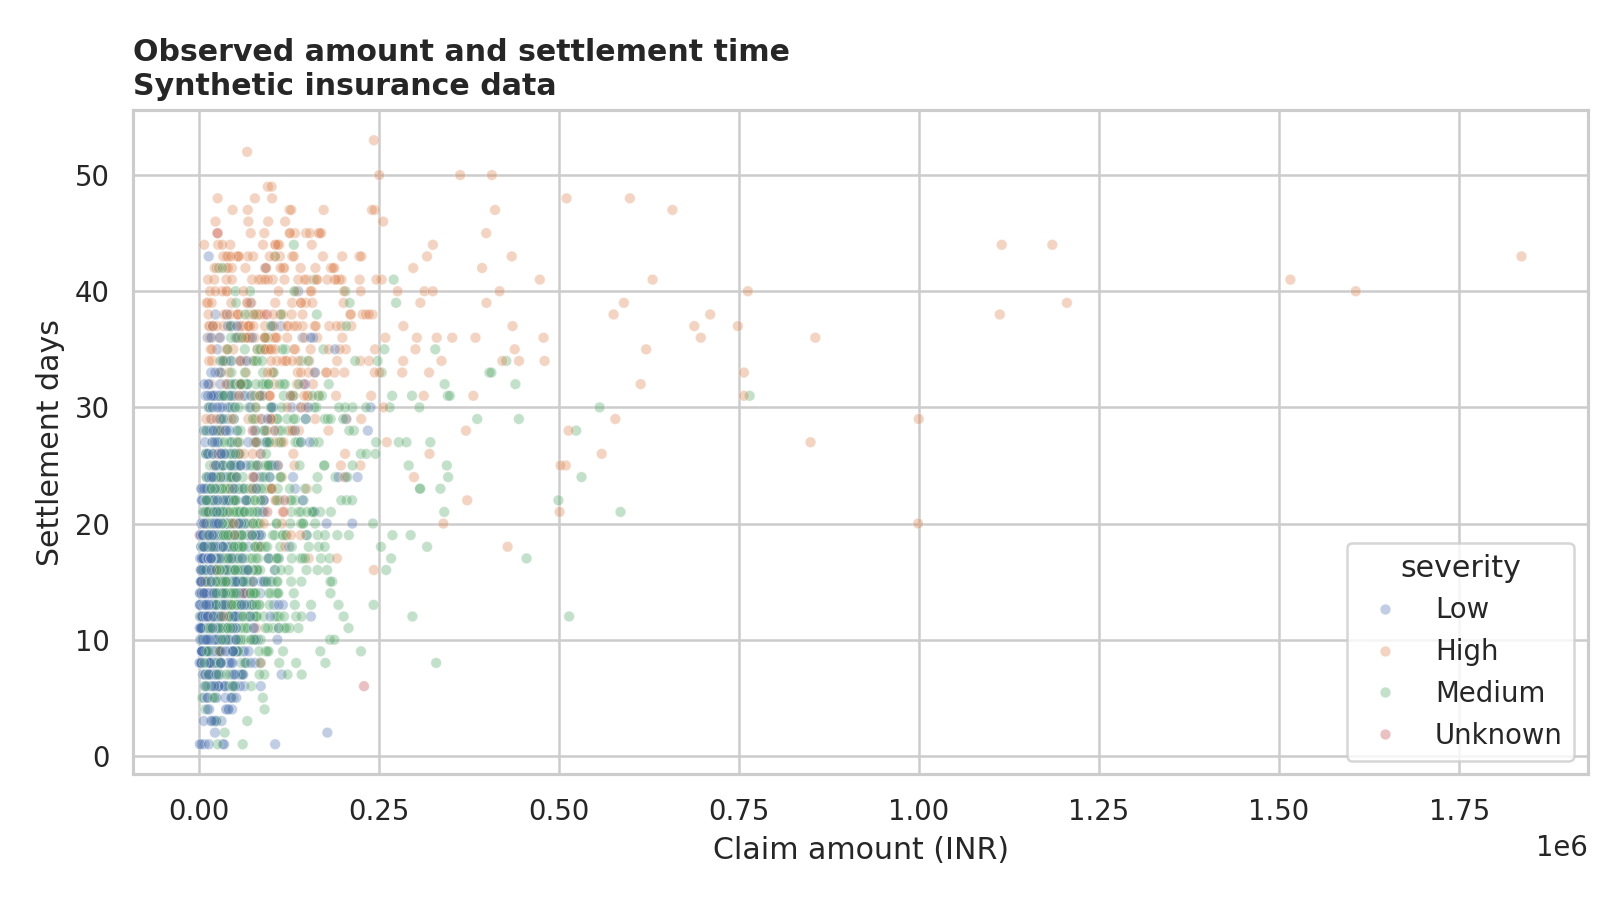

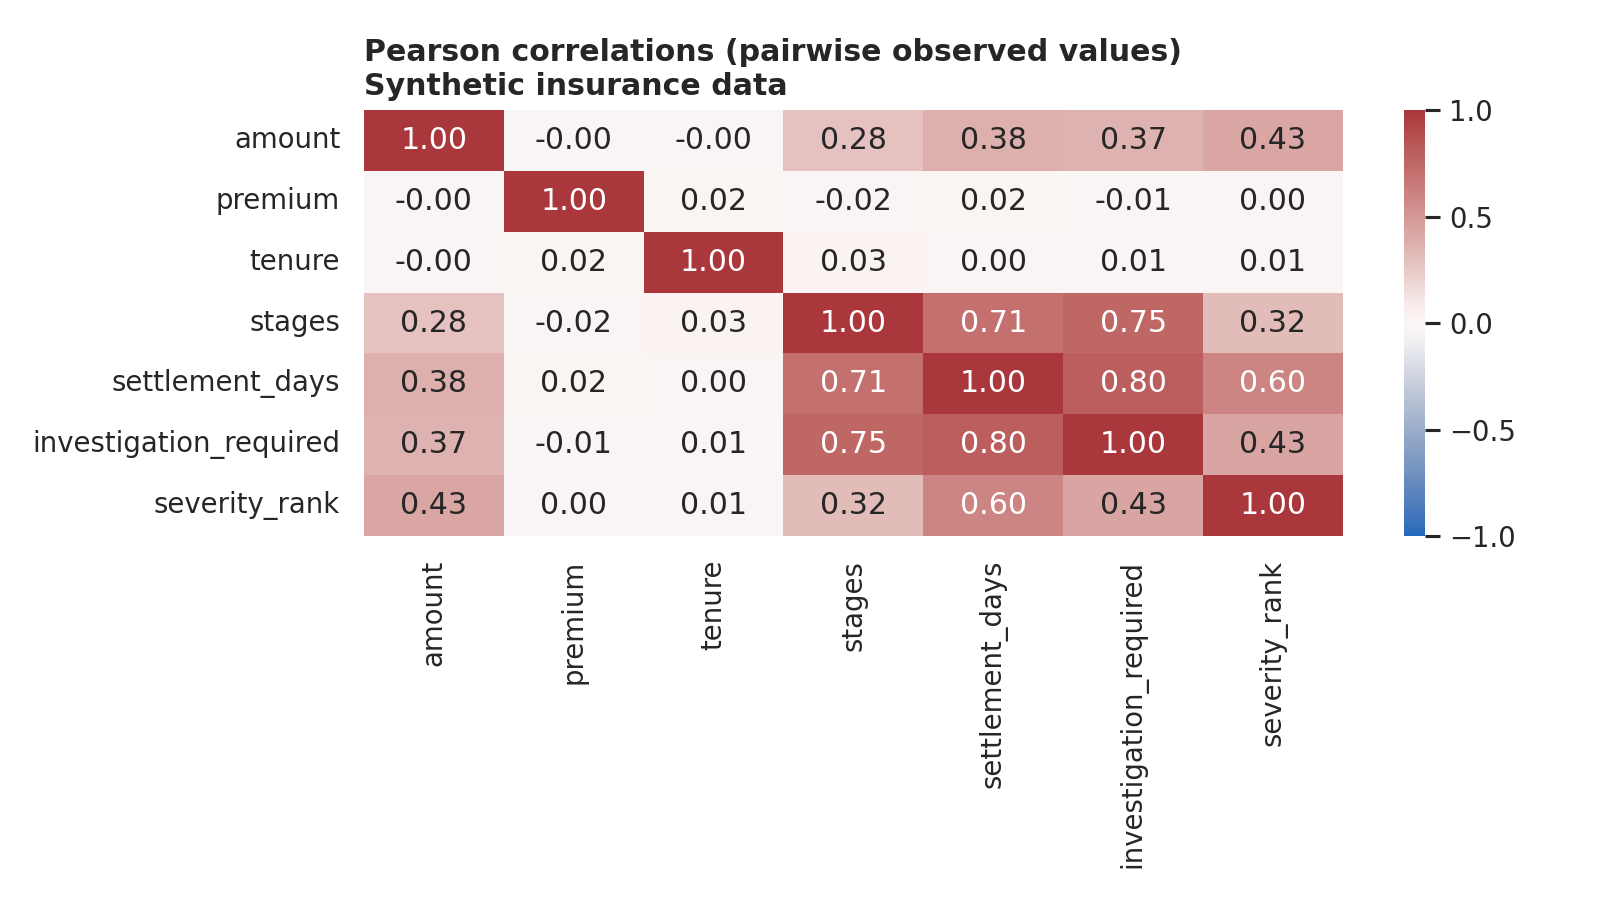

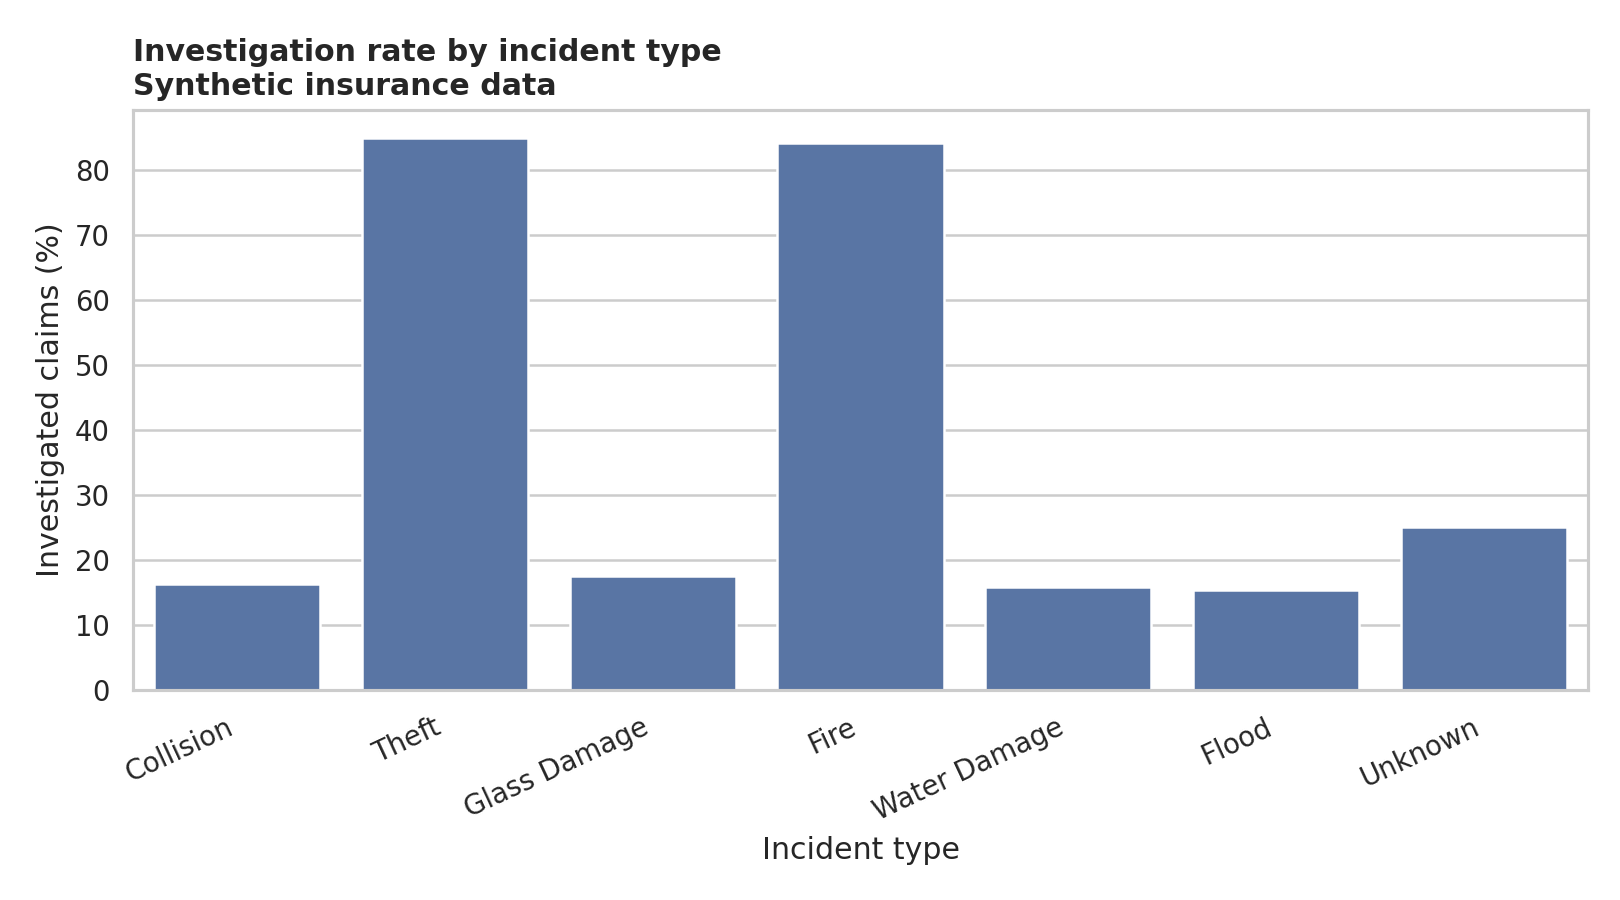

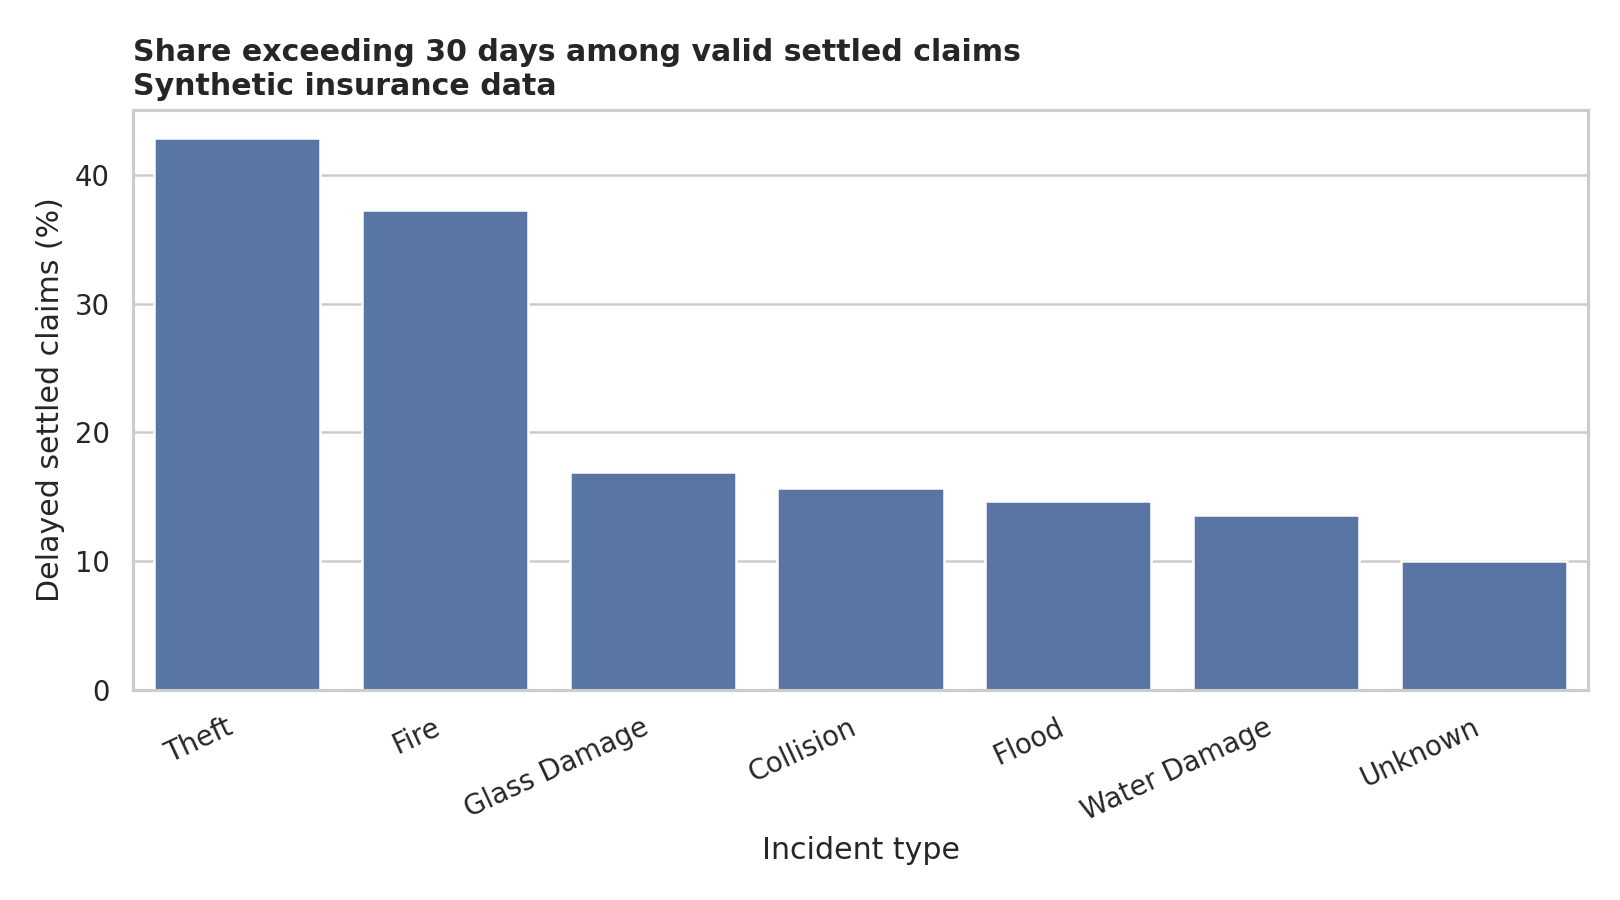

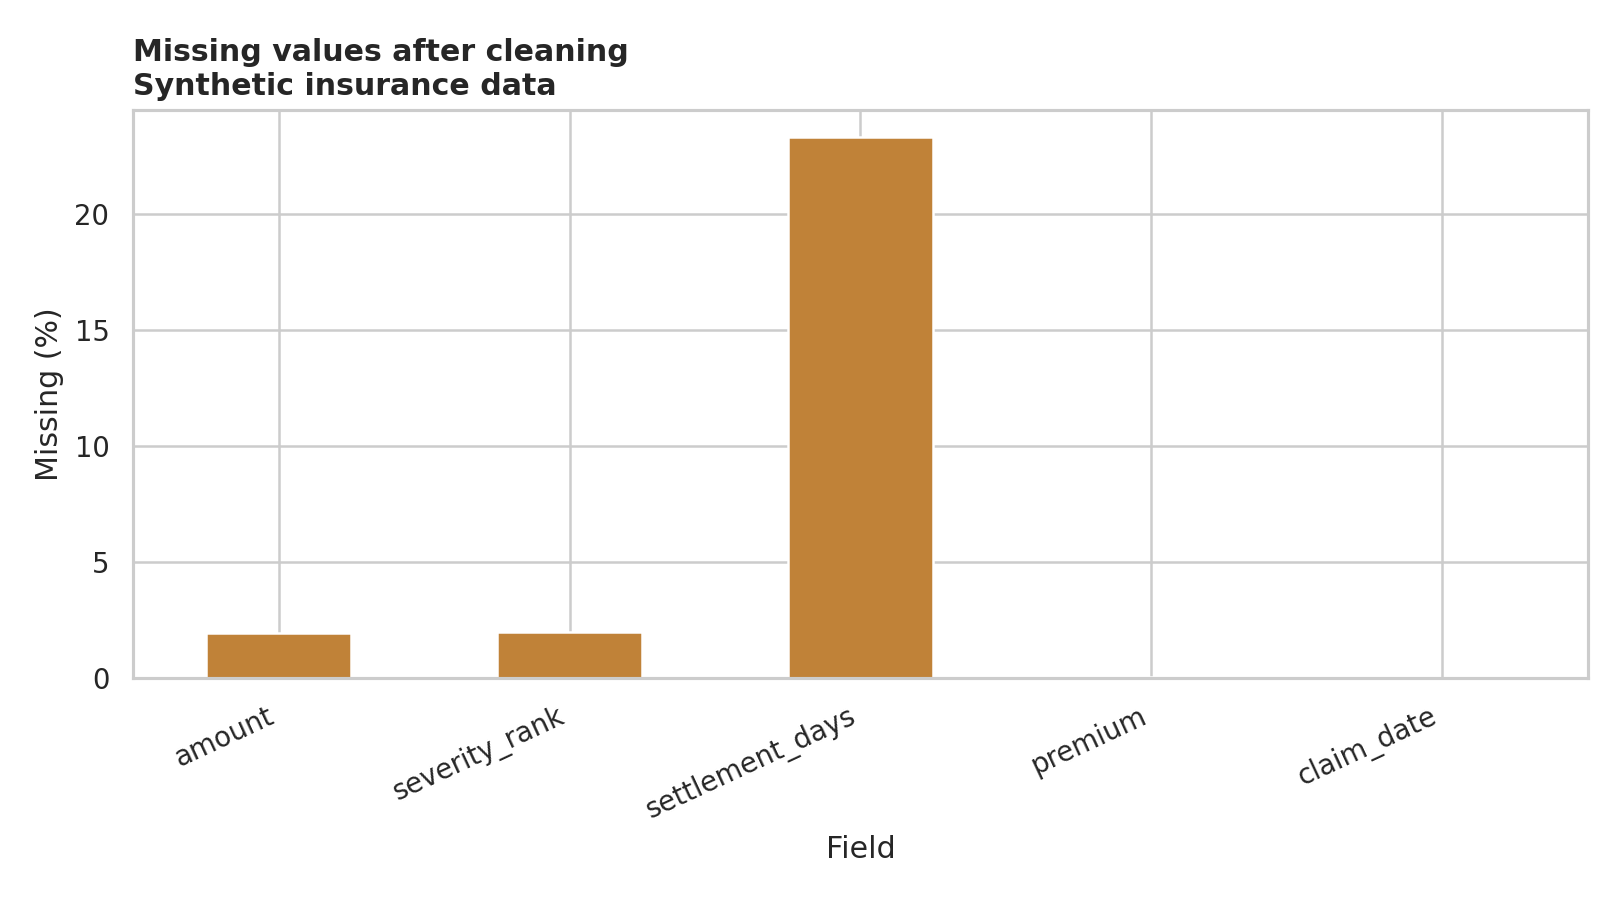

In [6]:
try:
    from IPython.display import Image, display
    def display_chart(name):
        display(Image(filename=str(ROOT / 'outputs/charts' / name)))
except ImportError:
    pass
for path in sorted((ROOT / 'outputs/charts').glob('*.png')):
    display_chart(path.name)

## 6. Six business questions
Answers are computed from the cleaned sample, not hardcoded findings. Region counts do not measure risk without exposure denominators; investigation is a proxy for effort.

In [7]:
answers = pd.read_csv(ROOT / 'outputs/tables/business_answers.csv')
for row in answers.itertuples(index=False):
    print(row.question)
    print(row.answer + '\n')
print('Stage count and duration:')
print(pd.read_csv(ROOT / 'outputs/tables/stage_count_summary.csv').to_string(index=False))

Which claim types have higher average value?
Property has the highest average observed amount: INR 146,259. Policy type is used for claim type; incident-level comparisons are also provided.

Which regions generate more claims?
South has 1,018 claims, the largest count. Counts are not risk rates: policy exposure and insured population differ.

What drives longer settlement time?
Theft has the highest mean settlement duration (28.3 days). Severity, stage count and investigation show associations in the plots; they do not establish causation.

Which stages create delay?
The brief supplies stage count, not timestamps or stage names. More stages can be compared with duration, but a specific bottleneck stage cannot be identified. Capture start/end timestamps for document review, investigation and approval.

How do claim values vary by severity?
Medium: INR 81,002; Low: INR 34,208; High: INR 184,526; Unknown: INR 51,104. Unknown details remain a separate category.

Which categories need more 

## 7. Encoded features and feature selection
The encoded export contains intake-oriented categories and numeric values, with claim_id retained as an identifier. Remove that ID before modelling. Unknown numeric values still need a train-fitted imputer. Keep type, region, incident type, severity, amount and premium for an interpretable descriptive feature set. Review correlated ordinal and one-hot severity representations before fitting a model. PCA is unnecessary here: the feature space is modest and retaining category meanings helps explain results. Never use settlement_days, delayed_claim, status or final stage count as intake predictors; these can leak later outcomes. Split by claim date and fit all transforms on training records for future prediction.

In [8]:
features = pd.read_csv(ROOT / 'data/cleaned/claim_features.csv')
print('Feature table shape:', features.shape)
print('Feature columns:', features.columns.tolist())
print(features.head(3).to_string(index=False))

Feature table shape: (3000, 29)
Feature columns: ['claim_id', 'amount_filled', 'amount_missing', 'premium', 'tenure', 'severity_rank', 'policy_type_Motor', 'policy_type_Property', 'policy_type_Unknown', 'region_name_Central', 'region_name_East', 'region_name_North', 'region_name_South', 'region_name_Unknown', 'region_name_West', 'incident_type_Collision', 'incident_type_Fire', 'incident_type_Flood', 'incident_type_Glass Damage', 'incident_type_Theft', 'incident_type_Unknown', 'incident_type_Water Damage', 'severity_High', 'severity_Low', 'severity_Medium', 'severity_Unknown', 'amount_band_Low', 'amount_band_Medium', 'amount_band_High']
claim_id  amount_filled  amount_missing  premium  tenure  severity_rank  policy_type_Motor  policy_type_Property  policy_type_Unknown  region_name_Central  region_name_East  region_name_North  region_name_South  region_name_Unknown  region_name_West  incident_type_Collision  incident_type_Fire  incident_type_Flood  incident_type_Glass Damage  incident_ty

## 8. Validation and interpretation
Check the claim grain, join preservation, valid numeric values, missing outcomes, and encoded categories. Results describe the generated sample only; the generator intentionally associates severity and investigations with duration.

In [9]:
assert df.claim_id.is_unique
assert len(df) == 3000
assert df.amount.dropna().ge(0).all()
assert df.settlement_days.dropna().ge(0).all()
assert df.loc[df.status.ne('Settled'), 'delayed_claim'].isna().all()
assert len(features) == len(df)
assert len(list((ROOT / 'outputs/charts').glob('*.png'))) == 12
print('All validation checks passed.')

All validation checks passed.
